In [1]:
import os
import textwrap

import clickhouse_connect
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Keeping the plots clean and easy to read.
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25
})

# Get the database name from the environment.
# If it is not set, we will use "discourse" by default.
DB = os.getenv("CLICKHOUSE_DATABASE", "discourse")

# Create a connection to ClickHouse.
# The values below are used as defaults for local development.
client = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST", "localhost"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER", "default"),
    password=os.getenv("CLICKHOUSE_PASSWORD", "clickhouse"),
)


# Small helper function to run a SQL query and directly get
# the result as a Pandas DataFrame.
def q(sql: str) -> pd.DataFrame:
    return client.query_df(sql)


# Topic titles can be very long, so this helper keeps them
# short when we display them in charts or tables.
def short(title: str, width: int = 55) -> str:
    return textwrap.shorten(title, width=width, placeholder="...")


# First, let's get a quick overview of our topic data.
# We want to know how many topics we have and when the oldest
# topic in the dataset was created.
q(
    f"""
    SELECT
        count() AS topics,
        min(created_at) AS oldest_topic
    FROM {DB}.v_dim_topics
    """
)

,topics,oldest_topic
0,287,2021-02-26 23:05:43.189


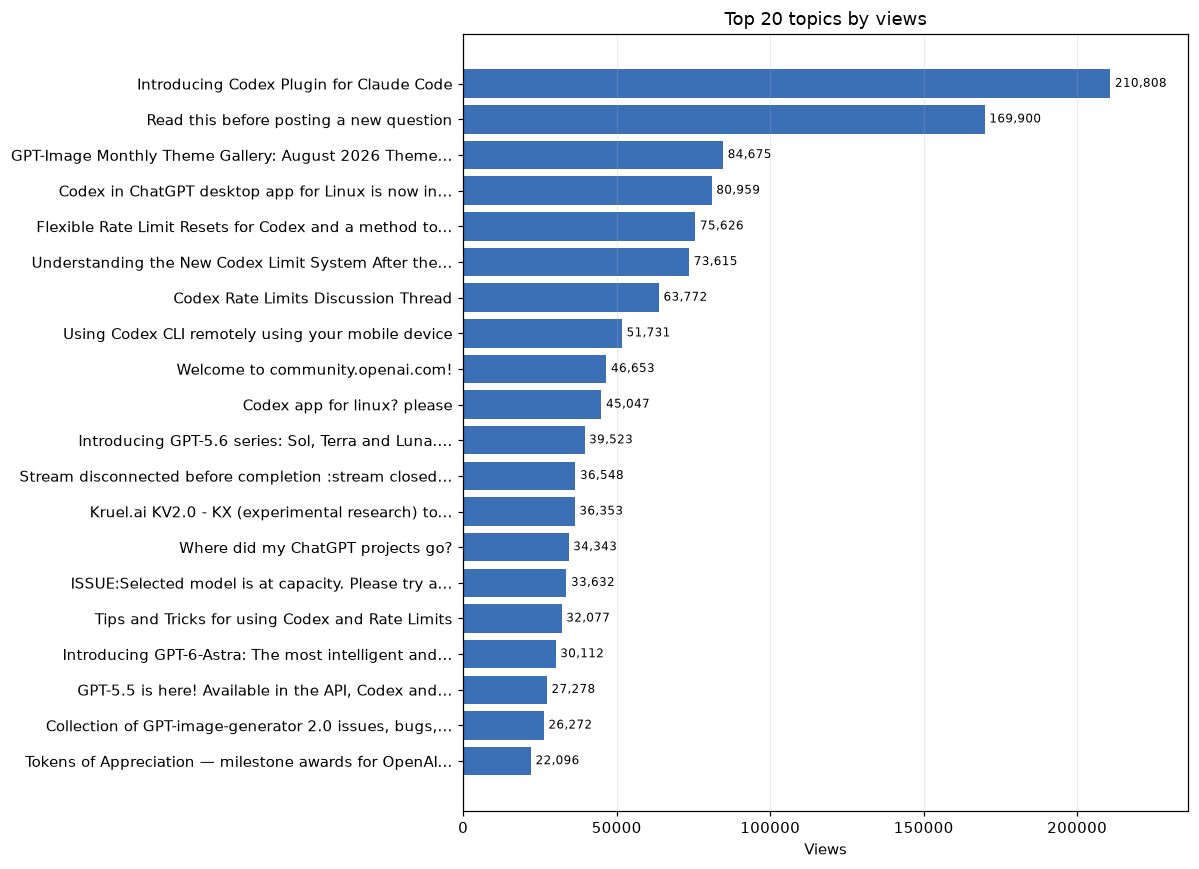

In [2]:
# Get the 20 most viewed topics.
# We also keep the topic title so we can show which discussions got the most attention.
top = q(f"""
SELECT topic_id, title, views, posts_count, like_count
FROM {DB}.v_dim_topics
ORDER BY views DESC, topic_id
LIMIT 20
""")

# Shorten long topic titles so they fit nicely on the chart.
top["label"] = top["title"].map(short)

# Sort by views so the least viewed topic appears at the bottom
# and the most viewed one appears at the top.
top = top.sort_values("views")

# Create a horizontal bar chart to make it easier to compare the topics.
fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.barh(
    top["label"],
    top["views"],
    color="#3b6fb6"
)

# Show the exact number of views at the end of each bar.
ax.bar_label(
    bars,
    labels=[f"{v:,}" for v in top["views"]],
    padding=3,
    fontsize=8
)

# Add clear labels and a title to explain what the chart is showing.
ax.set_title("Top 20 topics by views")
ax.set_xlabel("Views")
ax.set_ylabel("")

# Add a little extra space on the right so the view counts don't feel crowded.
ax.margins(x=0.12)

# Hide horizontal grid lines because they are not very useful for this chart.
ax.grid(axis="y", visible=False)

# Adjust the layout so nothing gets cut off.
plt.tight_layout()

# Display the final chart.
plt.show()

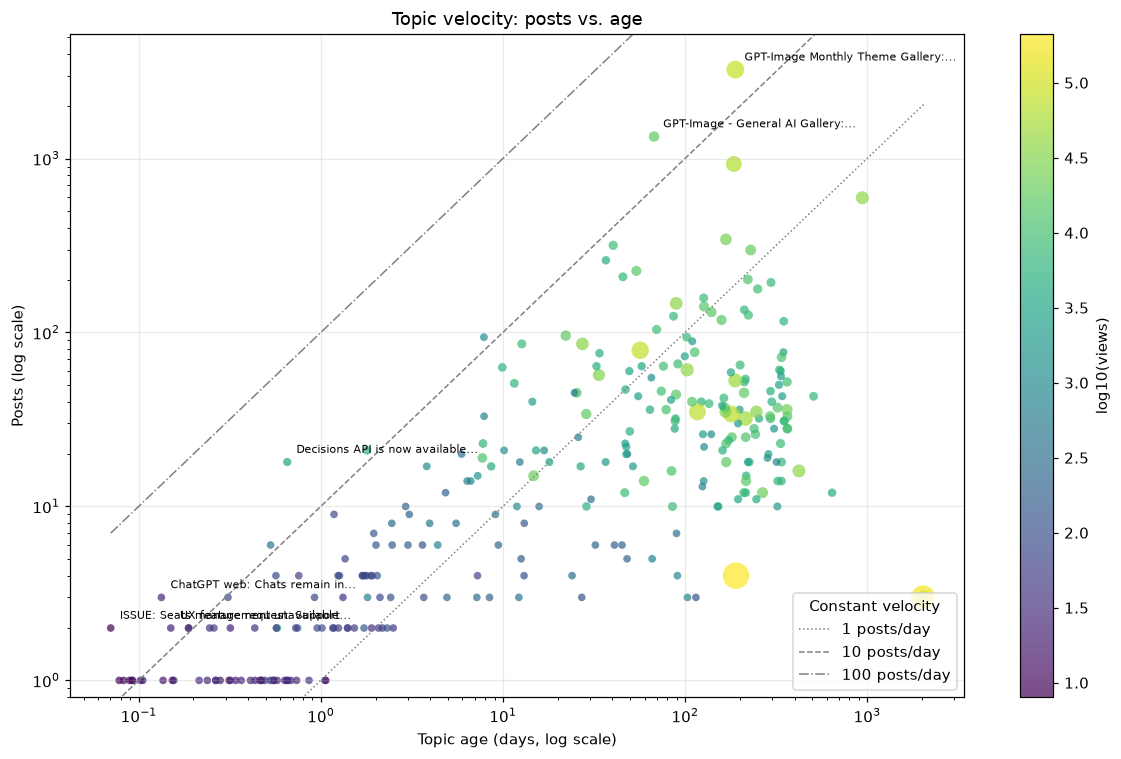

In [3]:
# Calculate how old each topic is and how quickly people posted in it.
# We only keep topics that have at least one post.
vel = q(f"""
SELECT
    topic_id, title, posts_count, views,
    greatest(
        dateDiff('second', created_at, now64(3)) / 86400.0,
        1.0 / 24
    ) AS age_days,
    posts_count / greatest(
        dateDiff('second', created_at, now64(3)) / 86400.0,
        1.0 / 24
    ) AS posts_per_day
FROM {DB}.v_dim_topics
WHERE posts_count > 0
""")


# Create a scatter plot to see how topic age relates to the number of posts.
fig, ax = plt.subplots(figsize=(11, 7))

# Use views to control the size of each bubble.
# Topics with more views will appear larger on the chart.
sizes = 25 + 275 * vel["views"] / max(vel["views"].max(), 1)

# Use the log of views for the bubble color so topics with very different
# view counts can still be compared more easily.
sc = ax.scatter(
    vel["age_days"],
    vel["posts_count"],
    s=sizes,
    c=np.log10(vel["views"] + 1),
    cmap="viridis",
    alpha=0.7,
    edgecolor="none"
)


# Create a smooth range of topic ages for drawing the reference lines.
xs = np.logspace(
    np.log10(vel["age_days"].min()),
    np.log10(vel["age_days"].max()),
    50
)

# These lines represent different posting speeds.
# For example, the 10 posts/day line shows where a topic would sit
# if it consistently received around 10 posts every day.
for rate, style in [(1, ":"), (10, "--"), (100, "-.")]:
    ax.plot(
        xs,
        rate * xs,
        style,
        color="grey",
        lw=1,
        label=f"{rate} posts/day"
    )


# Label the six topics with the highest posting speed.
# This helps us quickly identify the most active discussions.
for _, r in vel.nlargest(6, "posts_per_day").iterrows():
    ax.annotate(
        short(r["title"], 35),
        (r["age_days"], r["posts_count"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=7
    )


# Use log scales because topic ages and post counts can vary a lot.
ax.set_xscale("log")
ax.set_yscale("log")

# Give the chart a little breathing room around the data points.
ax.set_ylim(
    bottom=max(vel["posts_count"].min() * 0.8, 0.8),
    top=vel["posts_count"].max() * 1.6
)

# Add clear labels so the chart is easy to understand.
ax.set_xlabel("Topic age (days, log scale)")
ax.set_ylabel("Posts (log scale)")
ax.set_title("Topic velocity: posts vs. age")

# Show what each reference line represents.
ax.legend(title="Constant velocity", loc="lower right")

# Add a color scale to explain what the bubble colors represent.
fig.colorbar(sc, ax=ax, label="log10(views)")

# Adjust spacing and display the chart.
plt.tight_layout()
plt.show()

Each dot is one topic. Dots further right are older, and dots higher up have more posts.
A bigger or brighter dot means more views.
The dashed lines show constant speed. A dot above the "10 posts/day" line gets more than 10 new posts per day on average.
The six busiest topics are labelled.

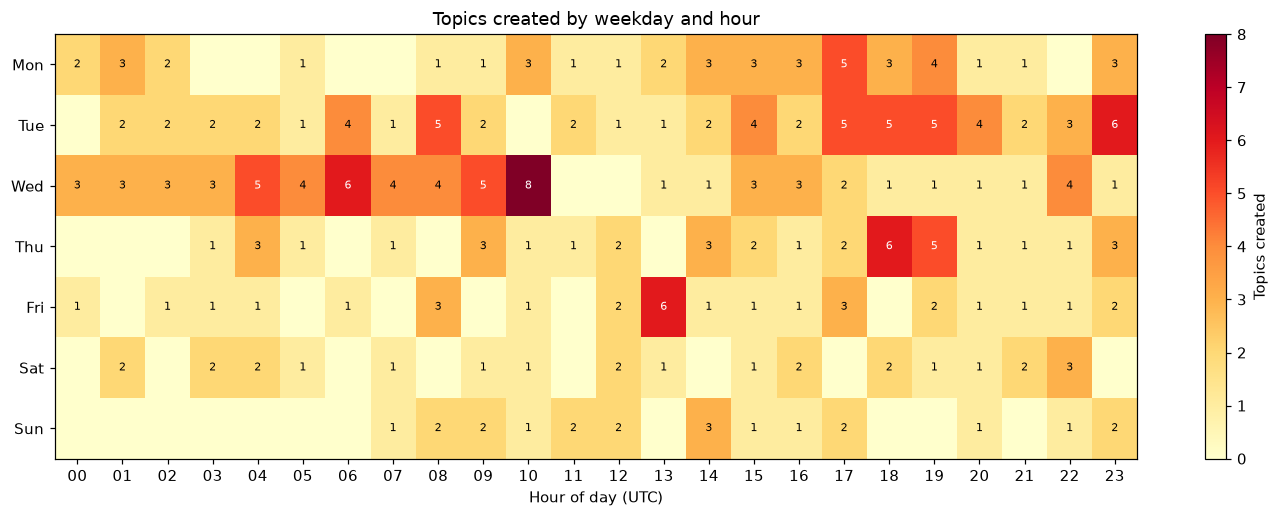

In [4]:
# Count how many topics were created on each day of the week and each hour.
# This helps us understand when the community is most active.
heat = q(f"""
SELECT
    toDayOfWeek(created_at) AS dow,
    toHour(created_at) AS hour,
    count() AS topics
FROM {DB}.v_dim_topics
GROUP BY dow, hour
""")


# Convert the query result into a weekday x hour grid.
# Missing combinations are filled with 0 because no topics were created
# during those particular time slots.
grid = (
    heat.pivot(index="dow", columns="hour", values="topics")
        .reindex(index=range(1, 8), columns=range(24))
        .fillna(0)
        .astype(int)
)

# Give the weekday numbers readable names for the chart.
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


# Create a heatmap so busy and quiet time periods are easy to spot.
fig, ax = plt.subplots(figsize=(13, 4.8))

im = ax.imshow(
    grid.values,
    aspect="auto",
    cmap="YlOrRd"
)

# Show all 24 hours on the X-axis.
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}" for h in range(24)])

# Show the days of the week on the Y-axis.
ax.set_yticks(range(7))
ax.set_yticklabels(days)

# Turn off the default grid because the heatmap already provides
# enough visual separation between the cells.
ax.grid(False)


# Display the actual topic count inside each cell.
# White text is used for darker cells and black text for lighter ones
# so the numbers remain easy to read.
for (i, j), v in np.ndenumerate(grid.values):
    if v:
        ax.text(
            j,
            i,
            v,
            ha="center",
            va="center",
            fontsize=7,
            color="white" if v > grid.values.max() * 0.6 else "black"
        )


# Add clear labels and explain that the timestamps are in UTC.
ax.set_xlabel("Hour of day (UTC)")
ax.set_title("Topics created by weekday and hour")

# Add a color scale showing how many topics were created.
fig.colorbar(im, ax=ax, label="Topics created")

# Adjust the layout so everything fits properly.
plt.tight_layout()
plt.show()

Each row is a weekday and each column is an hour of the day (UTC).
Darker or redder cells mean more topics were created in that slot. The numbers in the cells are the counts.
Blank cells mean no topics were created then.
The times are UTC. For India time (IST), add 5 hours 30 minutes.

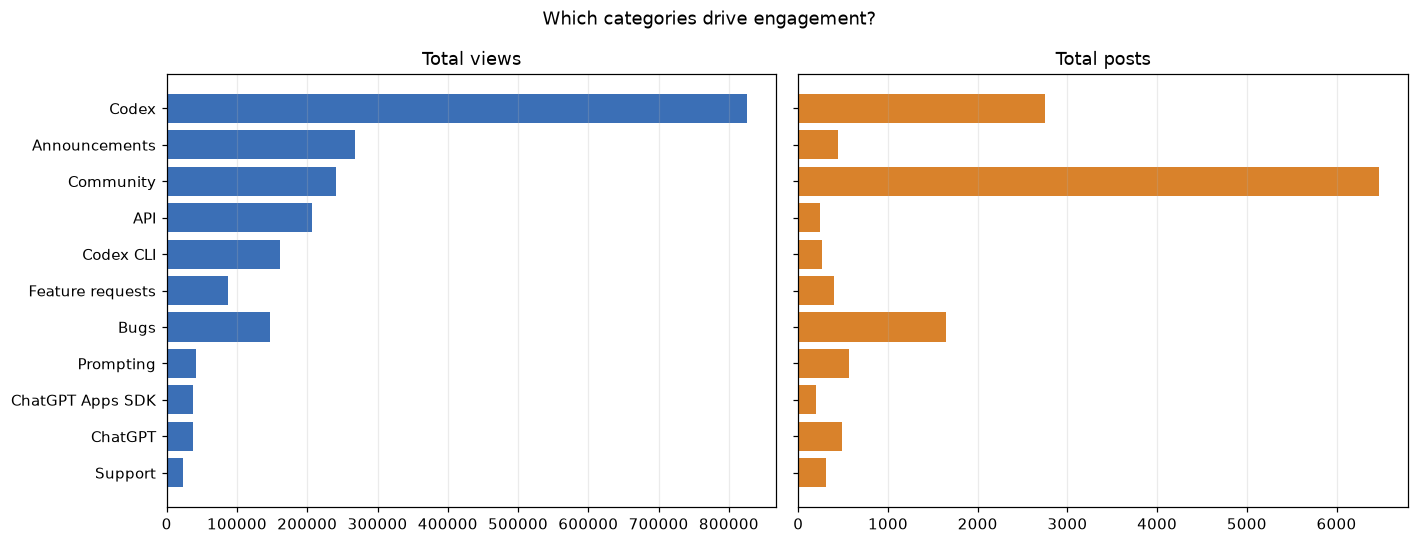

In [5]:
# Group topics by category so we can compare how much engagement
# each category is getting.
# We look at both views and posts to get a better picture of activity.
cat = q(f"""
SELECT
    coalesce(c.name, concat('Category #', toString(t.category_id))) AS category,
    count() AS topics,
    sum(t.posts_count) AS total_posts,
    sum(t.views) AS total_views
FROM {DB}.v_dim_topics AS t
LEFT JOIN {DB}.v_dim_categories AS c
    ON t.category_id = c.category_id
GROUP BY t.category_id, c.name
ORDER BY total_views DESC
LIMIT 12
SETTINGS join_use_nulls = 1
""")


# Reverse the order so the category with the highest engagement
# appears at the top of the horizontal charts.
cat = cat.iloc[::-1]


# Create two charts side by side:
# one for total views and another for total posts.
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
    sharey=True
)

# Show which categories attract the most views.
axes[0].barh(
    cat["category"],
    cat["total_views"],
    color="#3b6fb6"
)
axes[0].set_title("Total views")

# Show which categories generate the most discussion/posts.
axes[1].barh(
    cat["category"],
    cat["total_posts"],
    color="#d9822b"
)
axes[1].set_title("Total posts")


# Remove the horizontal grid lines to keep the charts clean.
for ax in axes:
    ax.grid(axis="y", visible=False)


# Add one overall title describing what we're trying to understand.
fig.suptitle("Which categories drive engagement?")

# Adjust spacing so the charts and labels fit properly.
plt.tight_layout()
plt.show()